<a href="https://colab.research.google.com/github/dy8656/cahmd_notebook_tutorials/blob/main/spin_dynamics_ase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atomistic spin dynamics with Cahmd and ASE

This notebook is a hands-on introduction to **atomistic spin dynamics**. Every magnetic atom carries
a classical spin $\mathbf{S}_i$ (a unit vector) with magnetic moment $\mu_i$, and the spins move
according to the **Landau-Lifshitz-Gilbert (LLG) equation**

$$\frac{d\mathbf{S}_i}{dt} = -\frac{\gamma}{1+\alpha^2}\left[\mathbf{S}_i \times \mathbf{B}_i^\mathrm{eff}
 + \alpha\, \mathbf{S}_i \times \left(\mathbf{S}_i \times \mathbf{B}_i^\mathrm{eff}\right)\right],
 \qquad \mathbf{B}_i^\mathrm{eff} = -\frac{1}{\mu_i}\frac{\partial \mathcal{H}}{\partial \mathbf{S}_i},$$

with the gyromagnetic ratio $\gamma = g\mu_B/\hbar$ and the Gilbert damping $\alpha$. The first term
makes the spins *precess* around the effective field, the second term makes them *relax* towards it.
The energy is the Heisenberg model with anisotropy and Zeeman energy,

$$\mathcal{H} = -\sum_{i\neq j} J_{ij}\, \mathbf{S}_i\cdot\mathbf{S}_j + \sum_i K\, (S_i^z)^2 - \sum_i \mu_i\, \mathbf{S}_i\cdot\mathbf{B}.$$

In *Cahmd* the sum over $i\neq j$ runs over **both** orders of every pair, and $K<0$ means an easy
axis along $z$ (`MCA=` in the input).

We use two Python libraries:

* **ASE** (Atomic Simulation Environment) to describe the crystal structure,
* **cahmd** (directory `python/` of the code) to turn the structure into an input of `CahmdDYN.x`,
  run it and read the results.

Contents:

1. A crystal structure with ASE
2. Larmor precession and damping
3. A domain wall
4. Magnetisation versus temperature

The runs take a few seconds to a few minutes on a laptop.

## 0. Setup

The package `cahmd` is used from this repository if it is not installed (`pip install -e python/`).
`CahmdDYN.x` has to be compiled (`./Install` and `./Cahmd -c DYN` in the main directory).
All runs write into the directory `runs/` next to this notebook.

### Running on Google Colab

The notebook also runs on [Google Colab](https://colab.research.google.com):

1. *File → Upload notebook* and choose this file.
2. Add a GitLab access token with the right `read_repository` as Colab secret `GITLAB_TOKEN`
   (key symbol on the left; enable *Notebook access*). Without it, the next cell asks for the token.
3. Run the cells in order. The next cell installs the compilers, downloads *Cahmd* and compiles
   `CahmdDYN.x`, which takes 5-10 minutes in every new Colab session.

On your own computer the next cell does nothing.

In [2]:
# Only on Google Colab: compilers, Cahmd source code, CahmdDYN.x and the Python interface
import os, sys, subprocess
from pathlib import Path

CAHMD_REPOSITORY = "https://gitlab.com/cahmd/cahmd.git"
CAHMD_BRANCH = "develop"

if "google.colab" in sys.modules:
    CAHMD = Path("/content/cahmd")
    LOG = "/content/cahmd_setup.log"

    def sh(cmd, env=None):
        with open(LOG, "a") as log:
            done = subprocess.run(cmd, shell=True, stdout=log, stderr=subprocess.STDOUT, env=env)
        if done.returncode != 0:
            print(open(LOG).read()[-3000:])
            raise RuntimeError(f"setup failed, see {LOG}")

    print("installing compilers and libraries ...")          # Colab runs Ubuntu 22.04
    sh("apt-get -qq update && apt-get -qq install -y gfortran libopenmpi-dev openmpi-bin "
       "libopenblas-openmp-dev liblapack-dev cmake ninja-build")

    if not CAHMD.exists():
        # read-only GitLab token: environment variable, Colab secret, or typed in; not stored
        token = os.environ.get("GITLAB_TOKEN")
        if not token:
            try:
                from google.colab import userdata
                token = userdata.get("GITLAB_TOKEN")
            except Exception:
                from getpass import getpass
                token = getpass("GitLab access token: ")
        print("downloading Cahmd ...")
        env = dict(os.environ, GIT_USER=os.environ.get("GITLAB_USER", "oauth2"), GIT_TOKEN=token)
        sh("git -c credential.helper='!f() { echo \"username=$GIT_USER\"; echo \"password=$GIT_TOKEN\"; }; f' "
           f"clone -q --depth 1 --branch {CAHMD_BRANCH} {CAHMD_REPOSITORY} {CAHMD}", env=env)

    print("compiling CahmdDYN.x (several minutes) ...")
    sh(f"cd {CAHMD} && cmake -S . -B build -G Ninja && cmake --build build --target DYN")

    sh("pip install -q ase")
    sys.path.insert(0, str(CAHMD / "python"))                 # the Python interface of the repository
    # Colab runs as root, which mpirun only accepts with these variables
    os.environ.update(CAHMD_HOME=str(CAHMD), OMPI_ALLOW_RUN_AS_ROOT="1",
                      OMPI_ALLOW_RUN_AS_ROOT_CONFIRM="1")
    print("ready:", CAHMD / "bin" / "CahmdDYN.x")

installing compilers and libraries ...
compiling CahmdDYN.x (several minutes) ...
ready: /content/cahmd/bin/CahmdDYN.x


In [3]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import constants as const
from scipy.optimize import curve_fit

try:
    import cahmd
except ImportError:                                   # not installed: take it from this repository
    sys.path.insert(0, str(Path.cwd().resolve().parents[1] / "python"))
    import cahmd

from ase import Atoms
from ase.build import bulk
from ase.visualize.plot import plot_atoms
from cahmd import CahmdStructure, Exchange, SpinDynamics
from cahmd.run import default_executable

print("CahmdDYN.x:", default_executable(), "found" if default_executable().exists() else "MISSING: ./Cahmd -c DYN")
RUNS = Path("runs")

CahmdDYN.x: /content/cahmd/bin/CahmdDYN.x found


## 1. A crystal structure with ASE

Iron crystallises in the body-centred cubic (bcc) structure with the lattice constant $a = 2.87$ Å.
ASE builds the **primitive cell** (one atom), and we give it a magnetic moment of $2.2\,\mu_B$.
Any other structure works the same way, for example `ase.io.read("my_structure.cif")`.

In [4]:
fe = bulk("Fe", "bcc", a=2.87)
fe.set_initial_magnetic_moments([2.2])        # muB per atom, along z
print(fe)
print("cell vectors (Angstrom):\n", fe.cell[:])

Atoms(symbols='Fe', pbc=True, cell=[[-1.435, 1.435, 1.435], [1.435, -1.435, 1.435], [1.435, 1.435, -1.435]], initial_magmoms=...)
cell vectors (Angstrom):
 [[-1.435  1.435  1.435]
 [ 1.435 -1.435  1.435]
 [ 1.435  1.435 -1.435]]


`CahmdStructure` combines the primitive cell with the number of repetitions along the three cell
vectors. Directions with periodic boundary conditions (`pbc`) are periodic in *Cahmd* as well.
`supercell()` returns all atoms of the simulated cluster as ASE `Atoms`.

number of spins: 64


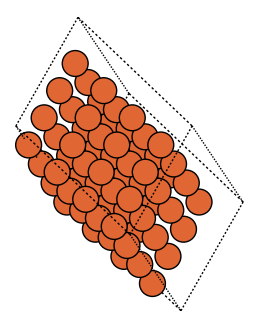

In [5]:
structure = CahmdStructure.from_ase(fe, size=(4, 4, 4))
cluster = structure.supercell()
print("number of spins:", len(cluster))

fig, ax = plt.subplots(figsize=(4, 4))
plot_atoms(cluster, ax, rotation="10x,20y,0z", radii=0.6)
ax.set_axis_off()

The exchange interaction $J_{ij}$ is usually given per **neighbour shell**: all neighbours at the same
distance have the same $J$. In bcc, every atom has 8 nearest neighbours at $a\sqrt{3}/2$ and 6
next-nearest neighbours at $a$.

In [6]:
shells = structure.shell_distances(3)
print("neighbour shells (Angstrom):", np.round(shells, 4))
print("in units of a:              ", np.round(shells / 2.87, 4))

exchange = Exchange.from_shells(structure, J=[19.5, 11.1])     # meV for the 1st and 2nd shell
for shell in (1, 2):
    pairs = [p for p in exchange.pairs if p.shell == shell]
    print(f"shell {shell}: {len(pairs)} neighbours, J = {pairs[0].J} meV")

neighbour shells (Angstrom): [2.4855 2.87   4.0588]
in units of a:               [0.866  1.     1.4142]
shell 1: 8 neighbours, J = 19.5 meV
shell 2: 6 neighbours, J = 11.1 meV


**Question:** How many neighbours does an atom have in the first three shells of an fcc lattice?
Check it with `bulk("Ni", "fcc", a=3.52)`.

## 2. Larmor precession and damping

All spins point along $x$ and a magnetic field $B = 10$ T points along $z$. Since all spins are
parallel, the exchange does not act on them: the whole magnet precesses like one big spin
(a *macrospin*) with the **Larmor frequency**

$$f_L = \frac{\gamma B}{2\pi} = \frac{g\mu_B B}{h} \approx 28\ \mathrm{GHz/T}\cdot B,$$

and the damping turns the magnetisation into the field direction.

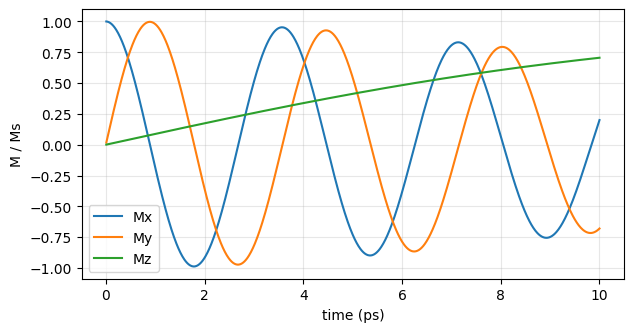

In [7]:
fe_x = bulk("Fe", "bcc", a=2.87)
fe_x.set_initial_magnetic_moments(None)
fe_x.set_initial_magnetic_moments([[2.2, 0.0, 0.0]])      # moment along x
macro = CahmdStructure.from_ase(fe_x, size=(3, 3, 3))

B, alpha = 10.0, 0.05
run = SpinDynamics(macro, Exchange.from_shells(macro, J=[19.5]), dt=0.5, steps=20000,
                   field=B, field_direction="z", damping=alpha, solver="midpoint", output_every=20)
larmor = run.run(RUNS / "larmor").steps            # time in fs, M in muB per atom
t = larmor["time"]

fig, ax = plt.subplots(figsize=(7, 3.5))
for c in ("Mx", "My", "Mz"):
    ax.plot(t / 1000, larmor[c] / 2.2, label=c)
ax.set_xlabel("time (ps)"); ax.set_ylabel("M / Ms"); ax.legend(); ax.grid(alpha=0.3)

We read the period from the zero crossings of $M_x$ and compare with the analytic result. For the
damping, the LLG equation of a macrospin that starts perpendicular to the field gives

$$M_z(t) = M_s \tanh\!\left(\frac{\alpha\,\gamma B\, t}{1+\alpha^2}\right).$$

simulation: f =  279.64 GHz
analytic:   f =  279.92 GHz


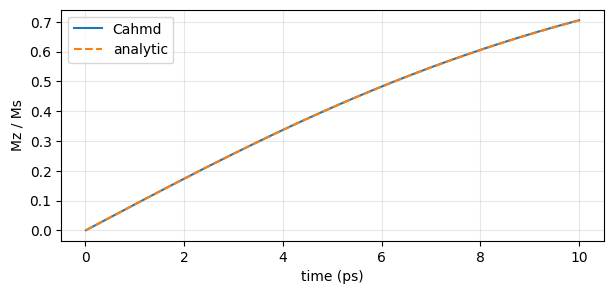

In [8]:
g = 2.0
gamma = g * const.physical_constants["Bohr magneton"][0] / const.hbar     # 1/(s T)

crossings = t[1:][np.diff(np.sign(larmor["Mx"])) != 0]
period = 2 * np.mean(np.diff(crossings))                                  # fs
print(f"simulation: f = {1e6 / period:7.2f} GHz")
print(f"analytic:   f = {gamma * B / (2 * np.pi) / 1e9:7.2f} GHz")

mz_exact = np.tanh(alpha * gamma * B * t * 1e-15 / (1 + alpha**2))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t / 1000, larmor["Mz"] / 2.2, label="Cahmd")
ax.plot(t / 1000, mz_exact, "--", label="analytic")
ax.set_xlabel("time (ps)"); ax.set_ylabel("Mz / Ms"); ax.legend(); ax.grid(alpha=0.3)

**Exercises**

* Double the field. How do the frequency and the relaxation time change?
* Set `damping=0.5`. What happens to the precession?

## 3. A domain wall

In a magnet with an easy axis, regions with opposite magnetisation (*domains*) are separated by a
**domain wall**, in which the spins turn gradually. The exchange wants a wide wall (neighbouring spins
almost parallel), the anisotropy a narrow one (as few spins as possible away from the easy axis).
The balance gives the profile

$$S^z(x) = -\tanh\!\left(\frac{x - x_0}{\delta}\right), \qquad \delta = a\sqrt{\frac{J}{|K|}}$$

for a chain with lattice constant $a$ (with *Cahmd*'s convention for $J$ above).

We set up a chain of 60 atoms with open ends, the left half pointing up, the right half down, and two
spins in the middle tilted along $x$. With a large damping the chain relaxes into the domain wall.

fit: wall centre 29.50, width delta = 7.06 lattice constants
theory: delta = sqrt(J/|K|) = 7.07


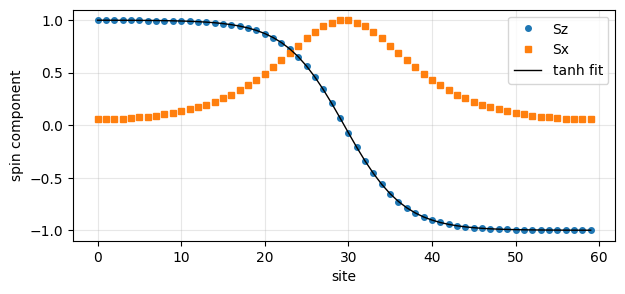

In [9]:
N = 60
chain = Atoms("Fe", positions=[[0, 0, 0]], cell=np.diag([2.5, 10.0, 10.0]), pbc=False)
chain.set_initial_magnetic_moments([2.2])

x = np.arange(N)
start = np.zeros((N, 3))
start[:, 2] = np.where(x < N // 2, 1.0, -1.0)
start[N // 2 - 1:N // 2 + 1, 0] = 1.0                      # tilt the two middle spins

def wall(x, x0, delta):
    return -np.tanh((x - x0) / delta)

def relax_wall(K, J=10.0, steps=40000):
    s = CahmdStructure.from_ase(chain, size=(N, 1, 1), atom_params={"Fe": {"MCA": f"{K} meV"}})
    run = SpinDynamics(s, Exchange.from_shells(s, J=[J]), dt=0.5, steps=steps, damping=1.0,
                       solver="sib", initial_spins=start, output_every=1000)
    spins = run.run(RUNS / f"wall_K{abs(K)}").final.arrays["spins"]
    return spins / np.linalg.norm(spins, axis=1)[:, None]

spins = relax_wall(K=-0.2)
(x0, delta), _ = curve_fit(wall, x, spins[:, 2], p0=[N / 2, 5])
print(f"fit: wall centre {x0:.2f}, width delta = {delta:.2f} lattice constants")
print(f"theory: delta = sqrt(J/|K|) = {np.sqrt(10.0 / 0.2):.2f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x, spins[:, 2], "o", ms=4, label="Sz")
ax.plot(x, spins[:, 0], "s", ms=4, label="Sx")
ax.plot(x, wall(x, x0, delta), "k-", lw=1, label="tanh fit")
ax.set_xlabel("site"); ax.set_ylabel("spin component"); ax.legend(); ax.grid(alpha=0.3)

**Exercise:** Make the anisotropy four times stronger (`K=-0.8`). By which factor does the wall
width change? Why is the agreement with the formula worse for very narrow walls?

In [10]:
spins_hard = relax_wall(K=-0.8)
(_, delta_hard), _ = curve_fit(wall, x, spins_hard[:, 2], p0=[N / 2, 3])
print(f"K = -0.8 meV: delta = {delta_hard:.2f}   (theory {np.sqrt(10.0 / 0.8):.2f})")
print(f"ratio of the widths: {delta / delta_hard:.2f}")

K = -0.8 meV: delta = 3.49   (theory 3.54)
ratio of the widths: 2.02


## 4. Magnetisation versus temperature

At finite temperature, a random thermal field is added to $\mathbf{B}^\mathrm{eff}$ (Langevin dynamics).
The spins fluctuate, and above the **Curie temperature** $T_C$ the magnet loses its magnetisation.
We take bcc Fe with exchange constants of the order of first-principles values and compute the average
magnetisation for several temperatures. Each point is a short run of 2 ps; we average over its second
half. *Cahmd* also reports the **spin temperature** $T_s$, measured from the spin configuration,
which should agree with the set temperature.

In [11]:
structure = CahmdStructure.from_ase(fe, size=(6, 6, 6))
exchange = Exchange.from_shells(structure, J=[19.5, 11.1])

temperatures = [100, 300, 500, 700, 900, 1100, 1300, 1500, 1800]
magnetisation, spin_temperature = [], []
for T in temperatures:
    run = SpinDynamics(structure, exchange, dt=0.5, steps=4000, temperature=T, damping=0.5,
                       solver="sib", output_every=20)
    steps = run.run(RUNS / f"MT_{T}").steps
    half = len(steps["time"]) // 2
    magnetisation.append(steps["|M|"][half:].mean() / 2.2)
    spin_temperature.append(steps["T_s"][half:].mean())
    print(f"T = {T:5d} K   M/Ms = {magnetisation[-1]:.3f}   T_s = {spin_temperature[-1]:6.0f} K")

T =   100 K   M/Ms = 0.977   T_s =    100 K
T =   300 K   M/Ms = 0.929   T_s =    299 K
T =   500 K   M/Ms = 0.876   T_s =    496 K
T =   700 K   M/Ms = 0.817   T_s =    692 K
T =   900 K   M/Ms = 0.749   T_s =    890 K
T =  1100 K   M/Ms = 0.653   T_s =   1092 K
T =  1300 K   M/Ms = 0.533   T_s =   1284 K
T =  1500 K   M/Ms = 0.325   T_s =   1481 K
T =  1800 K   M/Ms = 0.172   T_s =   1752 K


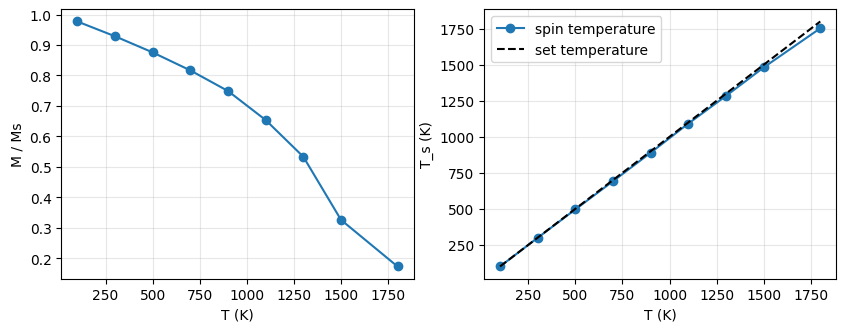

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(temperatures, magnetisation, "o-")
ax1.set_xlabel("T (K)"); ax1.set_ylabel("M / Ms"); ax1.grid(alpha=0.3)
ax2.plot(temperatures, spin_temperature, "o-", label="spin temperature")
ax2.plot(temperatures, temperatures, "k--", label="set temperature")
ax2.set_xlabel("T (K)"); ax2.set_ylabel("T_s (K)"); ax2.legend(); ax2.grid(alpha=0.3)

In **mean-field theory**, every spin feels the average field of its neighbours, which gives
(with the convention above, summing over all neighbours $j$ of an atom)

$$k_B T_C^\mathrm{MF} = \frac{2}{3}\sum_j J_{0j}.$$

Mean-field theory neglects fluctuations and overestimates $T_C$. The experimental Curie temperature of
iron is 1043 K.

In [13]:
kB = const.k / const.e * 1000          # meV/K
sum_J = 8 * 19.5 + 6 * 11.1           # meV, 8 first and 6 second neighbours
print(f"mean-field T_C = {2 / 3 * sum_J / kB:.0f} K")

mean-field T_C = 1722 K


**Exercises**

* Estimate $T_C$ from your curve. Compare with mean-field theory and with experiment.
* The cluster has only $6^3 = 216$ spins. How does the curve change for `size=(10, 10, 10)`?
  (The runs take longer.)
* Only two shells of $J$ are included. What happens to $T_C$ without the second shell?

## Where to go from here

* Any structure that ASE can read (CIF, POSCAR, ...) can be used with `CahmdStructure.from_ase`.
* Each run directory in `runs/` contains the complete input of *Cahmd* (`Cahmd.in`, `jrs.dat`),
  so the runs can be repeated or modified without Python: `mpirun -np 1 $CAHMD_HOME/bin/CahmdDYN.x`.
* The documentation of the input is in the *Cahmd* wiki (`doc/Cahmd_wiki`), the Python interface is
  described in `working_with_cahmd/python_ase`.